<a href="https://colab.research.google.com/github/WeridFire/QuantumComputing/blob/jago/assignment2/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Programming Assignment II
Quantum arithmetics, QFT, and quantum walks.

We use Qiskit's statevector simulator. The code and answers are in this notebook; the Grover bonus has its own notebook.

## Setup
Choose a Python kernel with `qiskit`, `numpy`, `matplotlib`, and `pylatexenc` installed, then run all cells from the top. If needed, run `%pip install qiskit numpy matplotlib pylatexenc` in a separate cell first.

Qubit 0 is the least significant bit. We write three-qubit states as $|q_2q_1q_0\rangle$, so $|100\rangle$ means 4. This follows [Qiskit's bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator

%matplotlib inline
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Qiskit:", qiskit.__version__)
print("NumPy:", np.__version__)

Qiskit: 2.5.2
NumPy: 2.4.6


### Circle notation
The filled area shows probability; the arrow shows phase. Here phase zero points right and positive angles turn counterclockwise. A zero amplitude has no phase arrow.

In [2]:
def circle_plot(state, title):
    state = Statevector(state)
    if not state.is_valid():
        raise ValueError("The state must be normalized.")
    n = state.num_qubits
    cols = min(8, len(state))
    rows = (len(state) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(1.55 * cols, 1.9 * rows),
                             squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal")
        ax.axis("off")
        if i >= len(state):
            continue
        amplitude = state.data[i]
        probability = abs(amplitude)**2
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.7"))
        ax.add_patch(plt.Circle((0, 0), abs(amplitude), color="steelblue", alpha=0.5))
        if probability > 1e-12:
            phase = np.angle(amplitude)
            ax.arrow(0, 0, 0.85 * np.cos(phase), 0.85 * np.sin(phase),
                     head_width=0.14, length_includes_head=True, color="navy")
        ax.set_title(f"|{i:0{n}b}>\nP = {probability:.3f}", fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# Task 1 - Quantum Arithmetics

Implement 3-qubit increment and decrement operators using IBM Qiskit, then inspect the states using circle notation.

## Task 1.1 - Increment and Decrement Operator

1. Prepare a superposition of quantum states using HAD QPU instructions. You can decide freely which superposition. This will determine the concurrent increment or decrement operator.
2. Plot the quantum states using the circle notation.
IBM Qiskit does not support visualization for this step; you will need to implement a Python routine to visualize the quantum states of our qubit. You can find a Python code to perform this task at 1.1.1 - Python Code for Circle Notation.
3. Perform an increment operation (by 1) +=
4. Plot the quantum states using the circular notation
5. Perform a decrement operation (by 1) -=
6. Plot the quantum states using the circular notation

> What to include. The chosen initial superposition, both circuits, and all three circle-notation plots.

### Our Solution
In binary addition, the lowest bit always flips. The next bit flips if the lowest bit was 1; the highest bit flips if both lower bits were 1. We apply the gates from the highest bit down, so the controls still contain the original bits.

Decrement is the inverse circuit: the same gates in reverse order.

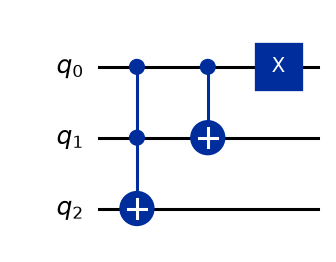

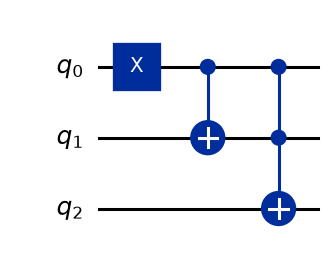

Increment and decrement: all 8 basis inputs passed.


In [3]:
increment = QuantumCircuit(3, name="+1")
increment.ccx(0, 1, 2)
increment.cx(0, 1)
increment.x(0)
decrement = increment.inverse()
decrement.name = "-1"

display(increment.draw("mpl"))
plt.close()
display(decrement.draw("mpl"))
plt.close()

# Check all eight inputs, including both wrap-around cases.
for x in range(8):
    initial = Statevector.from_int(x, 8)
    expected_plus = Statevector.from_int((x + 1) % 8, 8)
    expected_minus = Statevector.from_int((x - 1) % 8, 8)
    assert np.allclose(initial.evolve(increment).data, expected_plus.data)
    assert np.allclose(initial.evolve(decrement).data, expected_minus.data)
print("Increment and decrement: all 8 basis inputs passed.")

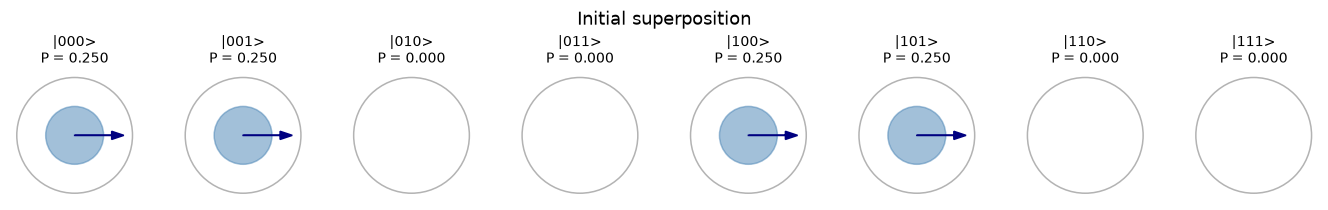

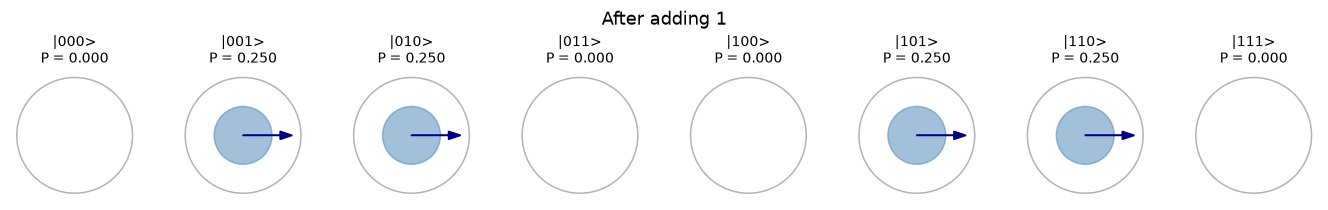

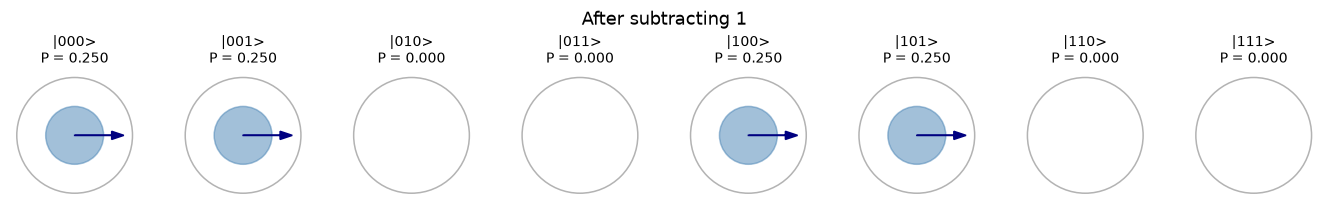

In [4]:
preparation = QuantumCircuit(3)
preparation.h(0)
preparation.h(2)
initial = Statevector.from_instruction(preparation)
after_increment = initial.evolve(increment)
after_decrement = after_increment.evolve(decrement)

circle_plot(initial, "Initial superposition")
circle_plot(after_increment, "After adding 1")
circle_plot(after_decrement, "After subtracting 1")

expected = np.zeros(8, dtype=complex)
expected[[0, 1, 4, 5]] = 0.5
assert np.allclose(initial.data, expected)
assert np.allclose(after_increment.data, np.roll(expected, 1))
assert np.allclose(after_decrement.data, initial.data)

The initial state is $(|0\rangle+|1\rangle+|4\rangle+|5\rangle)/2$. Each of these four values has probability $1/4$.

Adding 1 moves the amplitudes to 1, 2, 5, and 6. Subtracting 1 brings them back to the starting state. The probabilities and phases are unchanged; only the positions of the amplitudes change.

## Task 1.2 - Overflow, Underflow, and Negative Numbers

1. What happens on overflow during increment or underflow during decrement? Show both with an experiment.
2. Do increment and decrement also work with negative integers? Motivate the answer with an example.

> What to include. Overflow and underflow experiments, plus one explained negative-number example.

### Our Solution
Three qubits store eight possible bit strings. Arithmetic wraps around modulo 8: $7+1\to0$ and $0-1\to7$. These operations remain reversible.

Unsigned overflow: 7 + 1 -> 0
Unsigned underflow: 0 - 1 -> 7


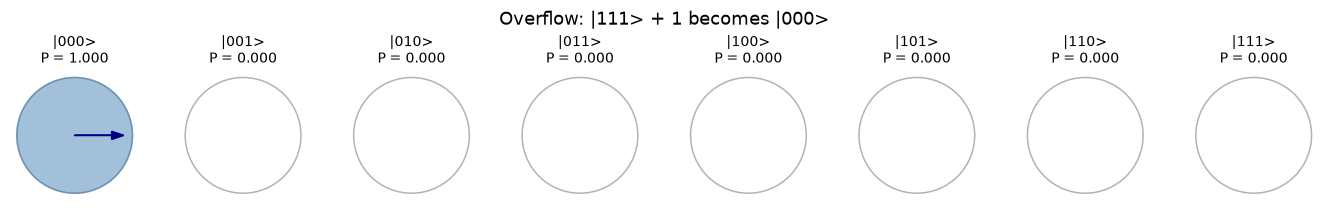

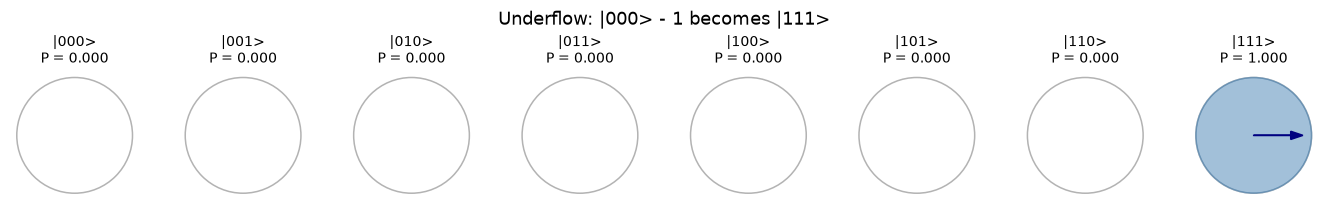


input  operation  result
   -2         +1      -1
   -2         -1      -3
   -1         +1       0
    3         +1      -4
   -4         -1       3


In [5]:
overflow = Statevector.from_int(7, 8).evolve(increment)
underflow = Statevector.from_int(0, 8).evolve(decrement)
print("Unsigned overflow: 7 + 1 ->", np.argmax(overflow.probabilities()))
print("Unsigned underflow: 0 - 1 ->", np.argmax(underflow.probabilities()))
circle_plot(overflow, "Overflow: |111> + 1 becomes |000>")
circle_plot(underflow, "Underflow: |000> - 1 becomes |111>")

# Two's complement: bit patterns 4..7 represent -4..-1.
def signed(x):
    return x if x < 4 else x - 8

print("\ninput  operation  result")
for x, operation, circuit in [(-2, "+1", increment), (-2, "-1", decrement),
                              (-1, "+1", increment), (3, "+1", increment),
                              (-4, "-1", decrement)]:
    final = Statevector.from_int(x % 8, 8).evolve(circuit)
    result = signed(int(np.argmax(final.probabilities())))
    delta = 1 if operation == "+1" else -1
    assert result == signed((x + delta) % 8)
    print(f"{x:5d}  {operation:>9}  {result:6d}")

Yes, negative integers work if we use **two's complement**. The bit strings 000–011 mean 0–3, while 100–111 mean −4–−1. The gates do not change; only our interpretation of the bits changes.

For example, −2 is 110. Increment gives 111 (−1), while decrement gives 101 (−3). The range is limited to −4 through 3: $3+1$ wraps to −4 and $-4-1$ wraps to 3. These results are correct modulo 8, but they are not ordinary integer results outside that range.

# Task 2 - Quantum Fourier Transform

Build a 4-qubit preparation circuit and QFT using Hadamard and controlled-phase gates, then analyze the resulting state.

The quantum Fourier transform is a crucial building block of many quantum algorithms, from Shor’s factoring algorithm to quantum phase estimation and simulations. As we saw in the lectures, QFT, like the conventional DFT and FFT, can be used to transform a function from the time domain into the frequency domain. Information about the periodic behavior of a function can be, for instance, encoded in the phases of the quantum states.

The goal of this exercise is to compute a 4-qubit QFT on a sinusoidal signal (encoded in the phase) using IBM Qiskit and plot the resulting state.  As part of this task, develop a four-qubit QFT and preparation circuit as in the circuit below.



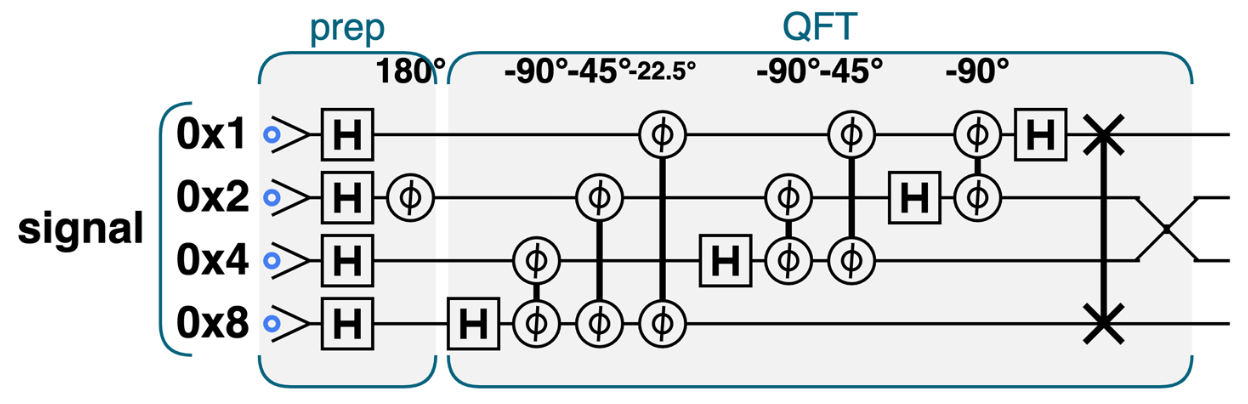

> Note that the IBM Qiskit provides a QFT function without implementing it from scratch. However, the Qiskit QFT code has a different ordering, as explained in the textbook, as pointed out in this GitHub issue: https://github.com/Qiskit/qiskit/pull/4849.

## Task 2.1 - QFT and Preparation Circuit

- Briefly describe the preparation circuit and QFT design.
- Print the complete circuit diagram.

### Our Solution
The labels 0x1, 0x2, 0x4, and 0x8 correspond to qubits 0, 1, 2, and 3. We apply H to all four qubits, then a phase of $\pi$ to qubit 1.

The transform uses H and controlled-phase gates with angles $-\pi/2$, $-\pi/4$, and $-\pi/8$, following the figure. The two final SWAP gates put the output bits in the usual order. With these negative angles, the transform uses the same sign as NumPy's FFT.

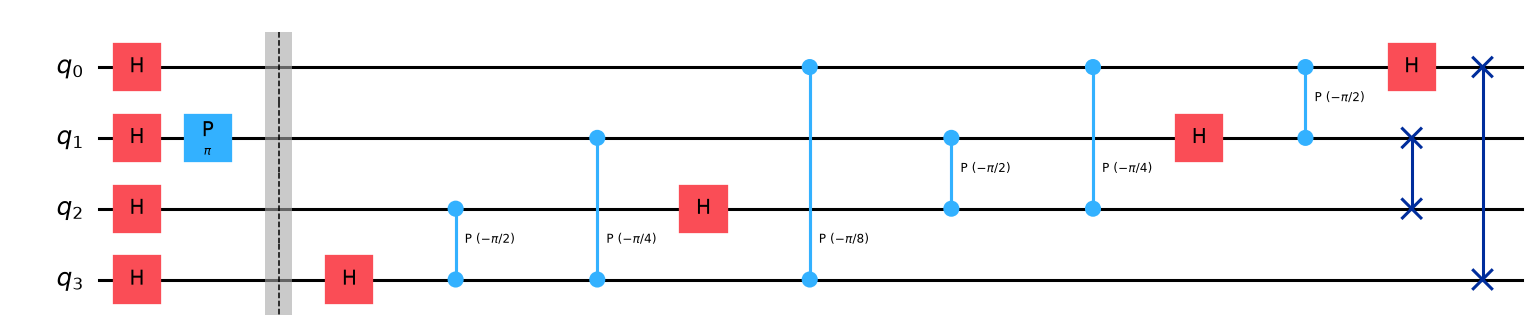

In [6]:
signal_circuit = QuantumCircuit(4, name="prepare")
signal_circuit.h(range(4))
signal_circuit.p(np.pi, 1)

qft = QuantumCircuit(4, name="QFT")
for target in reversed(range(4)):
    qft.h(target)
    for control in reversed(range(target)):
        qft.cp(-np.pi / 2**(target - control), control, target)
qft.swap(0, 3)
qft.swap(1, 2)

full_circuit = signal_circuit.copy()
full_circuit.barrier()
full_circuit.compose(qft, inplace=True)
display(full_circuit.draw("mpl", fold=-1))
plt.close()

## Task 2.2 - Circle Notation

1. Prepare the input and plot it using circle notation.
2. Identify the signal prepared by the circuit.
3. Perform the QFT and plot the resulting state using circle notation.

> What to include. Circle plots before and after the QFT, and an answer identifying the input signal.

### Our Solution
The input amplitudes repeat $[1,1,-1,-1]/4$, so the period is four samples. At integer positions $x$, this is
$$a_x=\frac{\sqrt{2}}{4}\cos\left(\frac{2\pi\cdot4x}{16}-\frac{\pi}{4}\right).$$
There are four cycles in the 16 samples. The probabilities are all $1/16$; the signs are stored as phases 0 and $\pi$.

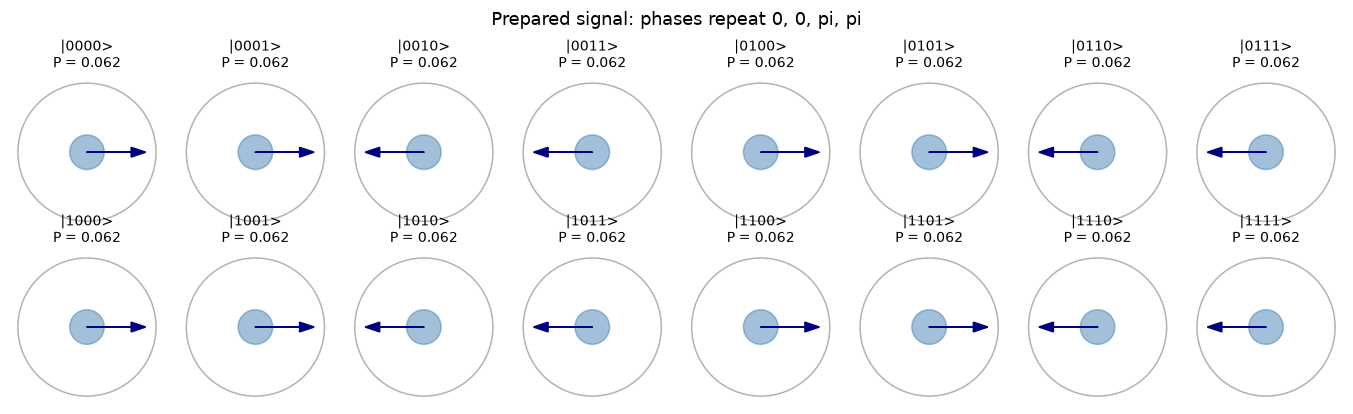

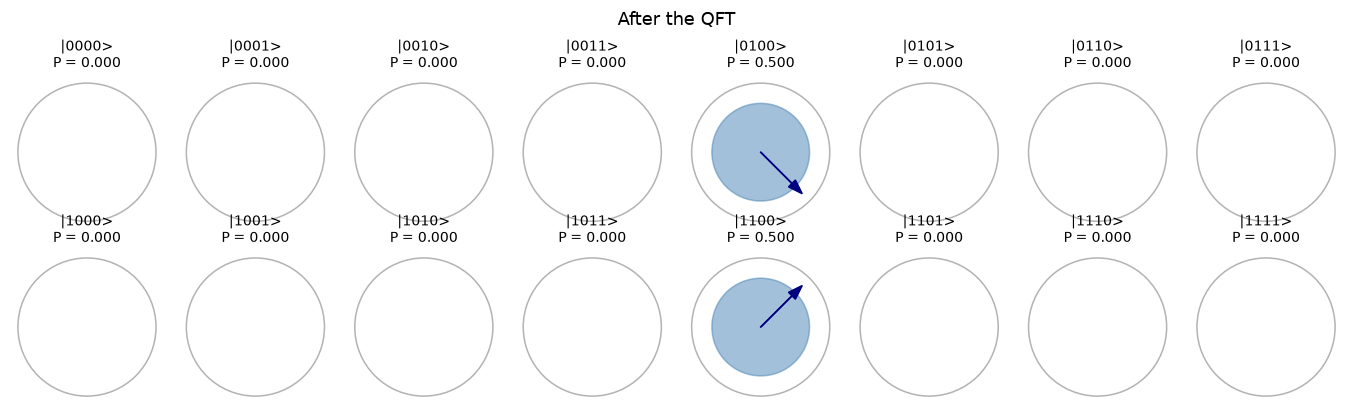

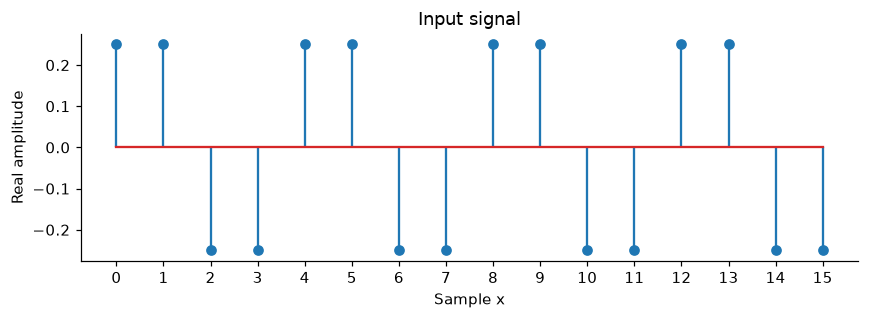

k= 4, amplitude=0.500-0.500j, probability=0.500
k=12, amplitude=0.500+0.500j, probability=0.500


In [7]:
signal = Statevector.from_instruction(signal_circuit)
transformed = signal.evolve(qft)
circle_plot(signal, "Prepared signal: phases repeat 0, 0, pi, pi")
circle_plot(transformed, "After the QFT")

x = np.arange(16)
expected_signal = np.sqrt(2) / 4 * np.cos(2 * np.pi * 4 * x / 16 - np.pi / 4)
assert np.allclose(signal.data, expected_signal)
fig, ax = plt.subplots(figsize=(8, 3))
ax.stem(x, signal.data.real)
ax.set(xlabel="Sample x", ylabel="Real amplitude", xticks=x, title="Input signal")
fig.tight_layout()
plt.show()

for k in np.flatnonzero(transformed.probabilities() > 1e-12):
    print(f"k={k:2d}, amplitude={transformed.data[k]:.3f}, "
          f"probability={transformed.probabilities()[k]:.3f}")

Only states 4 and 12 have nonzero probability, each with probability $1/2$. They represent frequencies +4 and −4 (since −4 is stored as 12 modulo 16). Both appear because our input is a real cosine.

Their amplitudes are $(1-i)/2$ and $(1+i)/2$, so their phases are −45° and +45°. Measuring gives one of the two frequency indices; it does not directly reveal these phases.

## Task 2.3 - Discussion

Discuss the results briefly and compare the QFT with the traditional DFT and FFT.

### Our Solution
We compare with `np.fft.fft(..., norm="ortho")`. This normalization keeps the sum of squared magnitudes equal to 1, as a quantum circuit must.

We also compare the entire circuit matrix with the DFT matrix. This checks the sign and bit order for every possible input, not only this signal.

Maximum QFT/FFT error: 2.482534153247273e-16
Full DFT matrix and inverse checks passed.


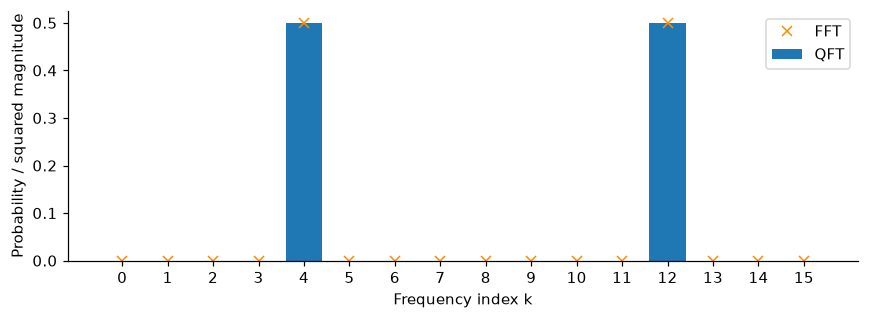

In [8]:
fft_result = np.fft.fft(signal.data, norm="ortho")
assert np.allclose(transformed.data, fft_result)
dft_matrix = np.exp(-2j * np.pi * np.outer(x, x) / 16) / 4
assert np.allclose(Operator(qft).data, dft_matrix)
assert np.allclose(transformed.evolve(qft.inverse()).data, signal.data)
print("Maximum QFT/FFT error:", np.max(np.abs(transformed.data - fft_result)))
print("Full DFT matrix and inverse checks passed.")

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(x, transformed.probabilities(), label="QFT")
ax.plot(x, abs(fft_result)**2, "x", color="darkorange", label="FFT")
ax.set(xlabel="Frequency index k", ylabel="Probability / squared magnitude", xticks=x)
ax.legend()
fig.tight_layout()
plt.show()

The QFT and FFT agree up to floating-point rounding. The DFT is the mathematical transform; FFT is an efficient classical algorithm for calculating it.

For $N=2^n$ samples, direct DFT calculation takes $O(N^2)$ operations and the FFT takes $O(N\log N)$. The QFT circuit uses $O(n^2)$ gates, or $O((\log N)^2)$. Here it has four H gates, six controlled-phase gates, and two SWAPs.

This does not mean that we can read a whole Fourier spectrum that quickly. The QFT stores the result in quantum amplitudes. Preparing an arbitrary input and recovering all output amplitudes can be expensive. It is useful when the larger algorithm only needs some information about the spectrum, such as a frequency.

# Bonus Exercise - Discrete Quantum Walk on a Line

In this bonus exercise, you will implement and investigate the Discrete Quantum Walk (DQW) algorithm using Qiskit or Cirq or another quantum computing software of your choice.

A quantum walk is the quantum analog of a classical random walk, but with underlying quantum effects, such as interference. It can be used in various quantum algorithms, such as quantum search and quantum speedup for graph traversal. By the end of the bonus exercise, you will understand how to represent and manipulate quantum states for discrete walks, leveraging quantum arithmetics primitives (albeit in a controlled way) and how quantum superposition and interference work in this context.

A nice introduction to the quantum walk and implementation in Cirq is provided at https://quantumai.google/cirq/experiments/quantum_walks

### Background

A Discrete Quantum Walk on a line consists of two quantum systems:

1. **Position space:** This keeps track of the walker's position on a discrete grid, which can be encoded using qubits. For instance, an **N-qubit system** can encode the position of a walker on one of the $2^N$ lattice points, ranging from $|0\rangle$ to $|2^{N}-1\rangle$.
2. **Coin space** determines whether the walk moves left or right. It can be represented by a **single qubit**, where $|0\rangle$ represents a step to the left and $|1\rangle$ represents a step to the right.

For a graph/lattice of size N = 8, for example, N = 3 qubits are required to encode each node and an extra qubit for the coin.

Each step in the walk is composed of two operations:

1. **Coin Flip:** This applies a Hadamard gate (or a custom coin operator) to the coin qubit, placing it in superposition.
2. **Conditional Increment/Decrement Operators:** Based on the value of the coin qubit, the position qubits are shifted left or right (decrement/increment) on the lattice.

Assume we have the following logic:

* If the coin qubit is $|1\rangle$, move to the right (increase position).
* If the coin qubit is $|0\rangle$, move to the left (decrease position).

However, we might build the shift operator with a controlled-NOT gate, which increments only when the control qubit is $|1\rangle$. If the coin qubit is $|0\rangle$, we apply a NOT gate to flip it to $|1\rangle$, and then apply the shift. After the shift, the NOT gate is applied again to restore the coin qubit to its original state. This technique helps implement the shift correctly for both $|0\rangle$ and $|1\rangle$ states of the coin qubit without changing the basic logic of the controlled operations. Note that NOT gates on the coin qubit are necessary to control the direction of the shift in the position register based on the coin's value. They are part of the controlled operations that conditionally apply shifts left or right and ensure that the quantum walk behaves as expected.

Indicatively, a simple step can be performed as follows, where $\uparrow$ and $\downarrow$ are a controlled version of increment and decrement operators.

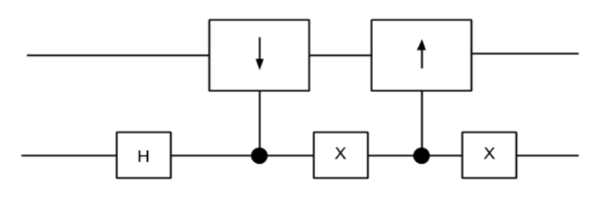

## Task B.1 - Quantum Walk Implementation

Implement a discrete quantum walk over 128 positions using seven position qubits and one coin qubit. Plot the circuit for ten iterations and compare it with Task 1.

### Our Solution
We start at position 64 with coin $|0\rangle$. Each step applies H to the coin, moves right if the coin is 1, and moves left if it is 0. We extend the carry logic from Task 1 to seven bits and add the coin as an extra control. Reversing the gate order gives decrement. Two X gates around it select coin 0 instead of coin 1.

The register wraps modulo 128, so technically it is a cycle. Our starts and step counts stay away from the ends: within these experiments it behaves like a line.

Controlled shifts: all 256 basis inputs passed.


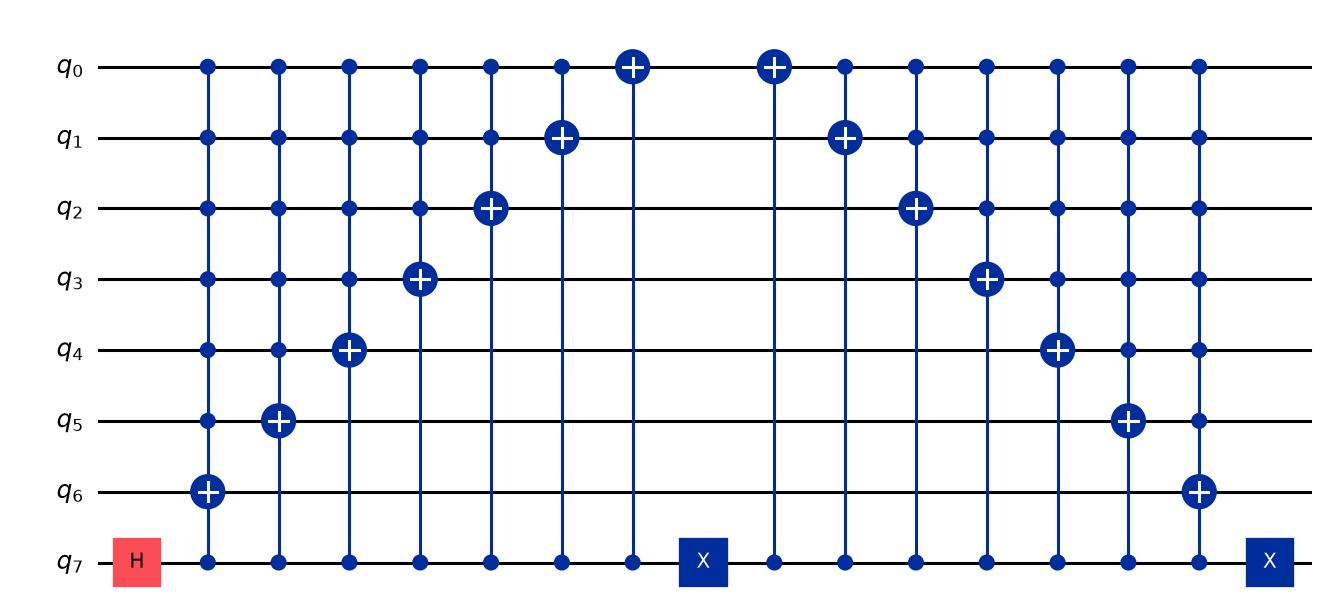

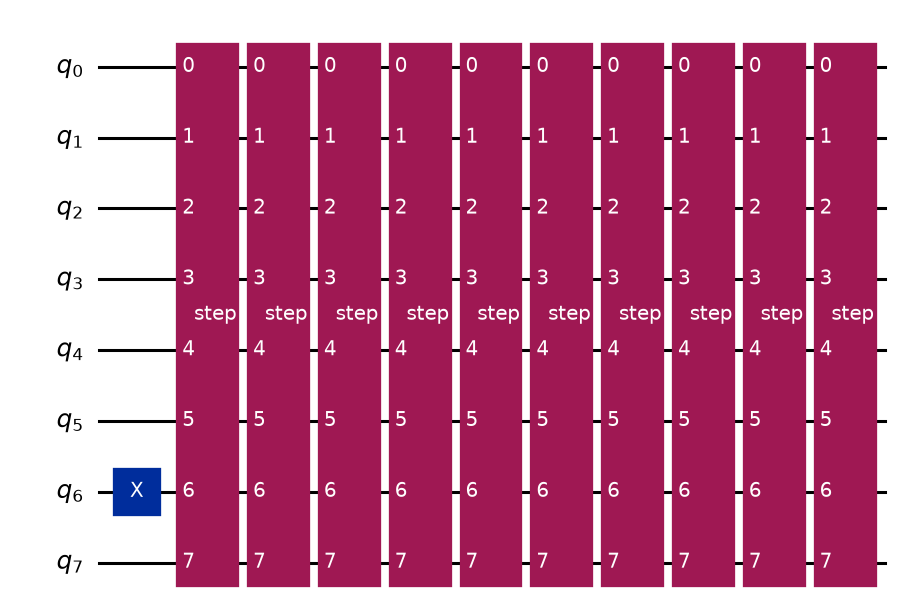

In [9]:
N_POS = 7
SIZE = 2**N_POS
COIN = 7
START = 64
positions = np.arange(SIZE)

# The same carry ladder as Task 1, now with the coin as an extra control.
right = QuantumCircuit(8, name="controlled +1")
for target in reversed(range(1, N_POS)):
    right.mcx([COIN] + list(range(target)), target)
right.cx(COIN, 0)

shift = QuantumCircuit(8, name="shift")
shift.compose(right, inplace=True)
shift.x(COIN)
shift.compose(right.inverse(), inplace=True)
shift.x(COIN)

def walk_step(angle=None):
    circuit = QuantumCircuit(8, name="step")
    if angle is None:
        circuit.h(COIN)
    else:
        circuit.ry(angle, COIN)
    circuit.compose(shift, inplace=True)
    return circuit

def walk(steps, start=START, superposition=False, angle=None, coin_one=False):
    if not isinstance(steps, int) or steps < 0 or not 0 <= start < SIZE:
        raise ValueError("Use a nonnegative integer step count and a position 0..127.")
    if superposition and start != START:
        raise ValueError("The two-position example starts at 64.")
    circuit = QuantumCircuit(8)
    for bit in range(N_POS):
        if (start >> bit) & 1:
            circuit.x(bit)
    if superposition:
        circuit.h(4)  # (|64> + |80>) / sqrt(2)
    if coin_one:
        circuit.x(COIN)
    step_gate = walk_step(angle).to_gate()
    for _ in range(steps):
        circuit.append(step_gate, range(8))
    return circuit

# Check both coin values and every position, including 0 and 127.
expected_shift = np.zeros((256, 256))
for coin in range(2):
    for position in range(SIZE):
        output = (position + (1 if coin else -1)) % SIZE
        expected_shift[coin * SIZE + output, coin * SIZE + position] = 1
assert np.allclose(Operator(shift).data, expected_shift)
print("Controlled shifts: all 256 basis inputs passed.")

display(walk_step().draw("mpl", fold=60))
plt.close()
display(walk(10).draw("mpl", fold=-1))
plt.close()

Each box in the ten-step drawing is the step circuit drawn above. There is no measurement between steps: keeping the amplitudes allows different paths to interfere.

## Task B.2 - Measurement Distribution

Plot the simulated distributions after 10, 20, and 30 iterations. Compare them with a classical random walk and discuss symmetry, spreading speed, and interference.

### Our Solution
We simulate the state, then sample 8,192 independent position measurements from it. The coin is left out of the recorded result. We also plot the exact probabilities, so sampling noise is visible.

For the classical walk, each step sends half the probability left and half right. To compare spreading, we print the root mean square distance from 64: $\sqrt{\sum_x p(x)(x-64)^2}$.

steps   mean shift   quantum RMS   classical RMS


   10       -2.453         5.473           3.162


   20       -5.592        10.844           4.472


   30       -8.361        16.254           5.477


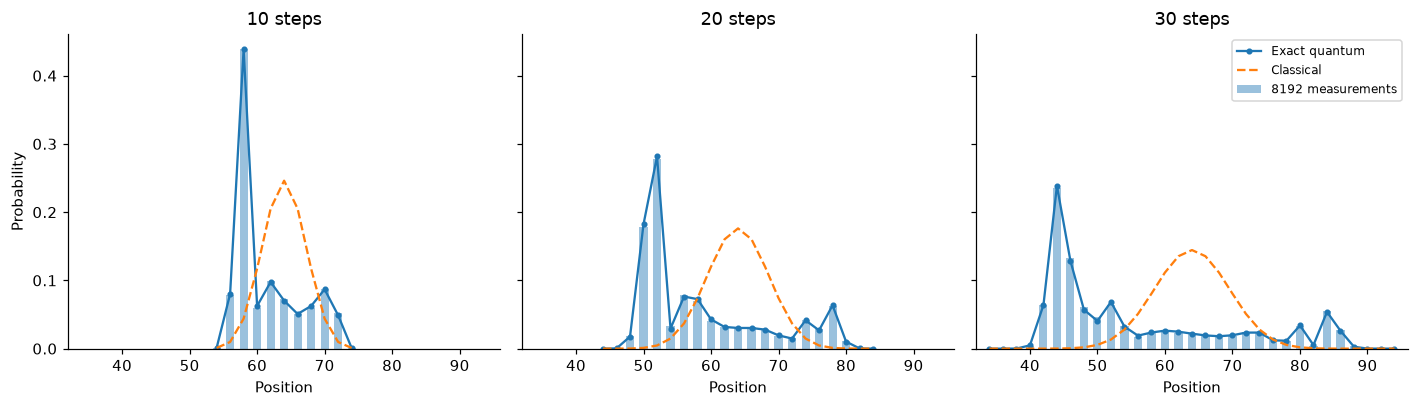

In [10]:
SHOTS = 8192

def position_probabilities(circuit):
    return Statevector.from_instruction(circuit).probabilities(list(range(N_POS)))

def classical_walk(steps):
    probability = np.zeros(SIZE)
    probability[START] = 1
    for _ in range(steps):
        probability = (np.roll(probability, -1) + np.roll(probability, 1)) / 2
    return probability

def mean_and_distance(probability):
    displacement = positions - START
    return np.dot(probability, displacement), np.sqrt(np.dot(probability, displacement**2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
walk_results = {}
print("steps   mean shift   quantum RMS   classical RMS")
for ax, steps in zip(axes, [10, 20, 30]):
    state = Statevector.from_instruction(walk(steps))
    probability = state.probabilities(list(range(N_POS)))
    state.seed(42 + steps)
    counts = state.sample_counts(SHOTS, qargs=list(range(N_POS)))
    observed = np.zeros(SIZE)
    for bits, count in counts.items():
        observed[int(bits, 2)] = count / SHOTS
    classical = classical_walk(steps)
    walk_results[steps] = probability
    assert np.isclose(probability.sum(), 1)
    assert sum(counts.values()) == SHOTS
    assert np.allclose(probability[1::2], 0, atol=1e-10)

    reachable = np.arange(START - steps, START + steps + 1, 2)
    ax.bar(reachable, observed[reachable], width=1.2, alpha=0.45, label="8192 measurements")
    ax.plot(reachable, probability[reachable], ".-", label="Exact quantum")
    ax.plot(reachable, classical[reachable], "--", label="Classical")
    ax.set(title=f"{steps} steps", xlabel="Position", xlim=(32, 96))
    shift_mean, distance = mean_and_distance(probability)
    _, classical_distance = mean_and_distance(classical)
    assert np.isclose(classical_distance, np.sqrt(steps))
    print(f"{steps:5d}   {shift_mean:10.3f}   {distance:11.3f}   {classical_distance:13.3f}")
axes[0].set_ylabel("Probability")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

The classical walk is symmetric and concentrated near the starting point. This quantum walk is not symmetric: with coin $|0\rangle$ it drifts left. The shape depends on both the coin operator and its initial state.

Quantum paths add as amplitudes, including their signs and phases, before we calculate probabilities. Some paths cancel and others reinforce each other. This interference produces the peaks and dips in the plot. The measurements fluctuate around the exact curve because we use a finite number of shots.

The table shows that the quantum distance grows roughly in proportion to the number of steps, while the classical distance is $\sqrt{t}$. The quantum walk spreads farther in the same number of steps. Each individual step still moves by only one position.

## Task B.3 - Initial Condition in Superposition

Initialize the walker in a superposition of two positions, plot the distribution after 30 iterations, and compare it with the earlier distributions.

### Our Solution
X on position qubit 6 prepares 64. H on qubit 4 then gives $(|64\rangle+|80\rangle)/\sqrt{2}$.

We compare this with the previous start at 64 and with a 50/50 mixture of separate walks starting at 64 and 80. The mixture adds probabilities; the superposition adds amplitudes.

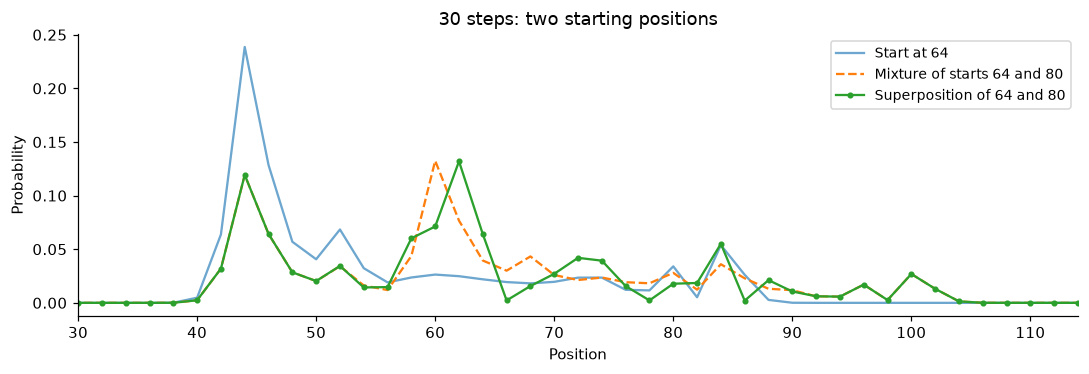

Largest probability difference from the mixture: 0.06127864681167017


In [11]:
two_starts = position_probabilities(walk(30, superposition=True))
single_64 = walk_results[30]
single_80 = position_probabilities(walk(30, start=80))
mixture = (single_64 + single_80) / 2

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(positions[::2], single_64[::2], label="Start at 64", alpha=0.65)
ax.plot(positions[::2], mixture[::2], "--", label="Mixture of starts 64 and 80")
ax.plot(positions[::2], two_starts[::2], ".-", label="Superposition of 64 and 80")
ax.set(xlabel="Position", ylabel="Probability", title="30 steps: two starting positions", xlim=(30, 114))
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
assert np.isclose(two_starts.sum(), 1)
assert not np.allclose(two_starts, mixture)
print("Largest probability difference from the mixture:", np.max(abs(two_starts - mixture)))

The two starts can reach some of the same positions after 30 steps. In that overlap, their amplitudes can reinforce or cancel each other. The superposition therefore differs from the mixture, as the plotted curves and printed difference show. Outside the overlap there is no contribution from the other start, so no cross-interference is possible.

## Task B.4 - ROTY and Biased Quantum Walk

Replace the coin operator with ROTY. Discuss how it changes the probability distribution and how it can produce a biased quantum walk.

### Our Solution
$R_Y(\theta)|0\rangle=\cos(\theta/2)|0\rangle+\sin(\theta/2)|1\rangle$. The angle changes how strongly the coin mixes left and right. After several steps, interference also matters, so the final distribution is not just a classical walk with a different coin probability.

We compare three angles and check how the result changes when the initial coin is flipped.

angle       mean shift   RMS distance


pi/4          -18.292         23.584


pi/2           -8.361         16.254


3pi/4          -1.789          8.311


pi/4, coin 1: mean shift = 18.292002001831772


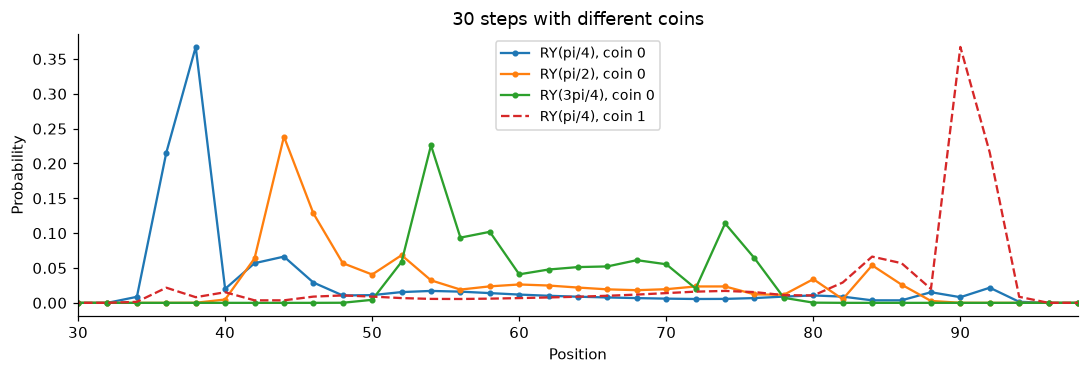

RY(0): deterministic left/right limits passed.


In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5))
print("angle       mean shift   RMS distance")
for label, angle in [("pi/4", np.pi / 4), ("pi/2", np.pi / 2),
                     ("3pi/4", 3 * np.pi / 4)]:
    probability = position_probabilities(walk(30, angle=angle))
    mean, distance = mean_and_distance(probability)
    print(f"{label:8s}   {mean:10.3f}   {distance:12.3f}")
    ax.plot(positions[::2], probability[::2], ".-", label=f"RY({label}), coin 0")

right_biased = position_probabilities(walk(30, angle=np.pi / 4, coin_one=True))
ax.plot(positions[::2], right_biased[::2], "--", label="RY(pi/4), coin 1")
print("pi/4, coin 1: mean shift =", mean_and_distance(right_biased)[0])
ax.set(xlabel="Position", ylabel="Probability", title="30 steps with different coins", xlim=(30, 98))
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# Limiting case: RY(0) is identity, so the coin never changes direction.
for coin_one, endpoint in [(False, START - 30), (True, START + 30)]:
    probability = position_probabilities(walk(30, angle=0, coin_one=coin_one))
    assert np.isclose(probability[endpoint], 1)
print("RY(0): deterministic left/right limits passed.")

For these initial conditions, $\theta=\pi/4$ gives a wider distribution and a stronger left drift than $\theta=3\pi/4$. Starting the coin at 1 reverses the bias in the $\pi/4$ example.

Thus one way to make a biased walk is to start the coin at 0 and use $R_Y(\pi/4)$ for a left bias, or start it at 1 for a right bias. The limiting case $\theta=0$ is easy to check: the coin never changes and the walker moves in one direction every step.

# Bonus Exercise - Grover's Algorithm

Complete this bonus in the separate notebook supplied with the assignment.

### Our Solution

The completed supplied notebook is [grover_assignment/grovers_algorithm_qiskit.ipynb](grover_assignment/grovers_algorithm_qiskit.ipynb).

## AI Assistance Disclosure

### Tools and models used
OpenAI Codex (GPT-6), using the Ponytail plugin to keep the implementation small.

### Per-task usage
AI helped write and explain the arithmetic circuits, circle plots and checks.

### Prompts or interaction summary


### Validation

**Sources:** [Canvas Assignment II](https://canvas.kth.se/courses/63895/assignments/393370) and [IBM Qiskit bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).
